# B8 — Trực quan hóa Tổng hợp Báo cáo, Phân tích Lỗi (Error Analysis) & Demo Tương tác

**Mục tiêu của Bước 8 (B8) — Hoàn thiện toàn bộ hình ảnh & minh họa cho Báo cáo và Bảo vệ Đồ án:**
1. **Xuất 6 biểu đồ tổng kết chuẩn ấn phẩm (300 DPI `.png` + `.pdf`) tại `workspace_outputs/figures/B8_final_report/`:**
   - `B8_01_tien_trinh_3_vong_va_ablation`: Tiến trình `Run 1 → Run 2 → Run 3` đặt cạnh mốc **Supervised Baseline** và **Final Ensemble**.
   - `B8_02_radar_charts_7_models`: Lưới Radar 5 trục cho 7 mô hình qua 3 vòng + ô tổng kết Baseline vs Run 3 vs Ensemble.
   - `B8_03_heatmap_f1_theo_lop`: Heatmap chi tiết F1 từng lớp ESG của 7 mô hình Run 3 + 4 chiến lược Ensemble.
   - `B8_04_confusion_matrix_best_va_ensemble`: Ma trận nhầm lẫn kép (Số lượng & Recall %) của Best Single Model và Best Final Ensemble.
   - `B8_05_tradeoff_hieu_nang_va_toc_do`: Biểu đồ Trade-off Macro-F1 vs Latency (ms/câu) kèm đường biên Pareto.
   - `B8_06_calibration_reliability`: Biểu đồ hiệu chuẩn xác suất (Reliability Diagram & ECE).
2. **Phân tích Lỗi chuyên sâu (Error Analysis):** Thống kê cặp nhầm lẫn phổ biến nhất, so sánh số câu Ensemble sửa đúng cho Single Model và xuất `metrics/B8_top15_errors.csv`.
3. **Demo phân loại văn bản ESG tương tác ngay trên JupyterLab (`ipywidgets`):** Nhập văn bản tiếng Việt bất kỳ hoặc chọn nhanh 4 câu mẫu ESG → hiển thị nhãn dự đoán, xác suất 4 lớp và phiếu bầu của từng mô hình.

In [1]:
# Bước 8.1: Khởi tạo môi trường & nạp toàn bộ dữ liệu tổng hợp từ Bước B7
import gc
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    MODEL_REGISTRY,
    ensure_directories,
    get_figure_dir,
    PROCESSED_DATA_DIR,
    CHECKPOINTS_DIR,
    METRICS_DIR,
    LABEL_NAMES,
    ID2LABEL,
    LABEL_NAMES_VI,
)
from src.evaluator import ESGEvaluator
from src.model_wrapper import ESGModelWrapper
from src.preprocessing import VietnameseESGPreprocessor
from src.viz_utils import (
    ESG_PALETTE,
    plot_ablation_and_3rounds_progress,
    plot_radar_charts_grid,
    plot_per_class_f1_heatmap,
    plot_dual_confusion_matrix,
    plot_accuracy_latency_tradeoff,
    plot_calibration_reliability_diagram,
)

ensure_directories()
cfg = PipelineConfig(hardware_mode="balanced", model_preset="full_7")
FIG_DIR = get_figure_dir("B8")

summary_all_path = METRICS_DIR / "summary_all_runs.csv"
b7_summary_path = METRICS_DIR / "B7_run3_and_ensemble_summary.csv"
ens_json_path = METRICS_DIR / "run3_final_ensemble_eval.json"
assert summary_all_path.exists() and ens_json_path.exists(), "Hãy chạy xong Bước B7 trước khi chạy B8!"

all_runs_df = pd.read_csv(summary_all_path)
b7_summary_df = pd.read_csv(b7_summary_path)
test_df = pd.read_csv(PROCESSED_DATA_DIR / "test_clean.csv")
with open(ens_json_path, "r", encoding="utf-8") as f:
    ens_eval_bundle = json.load(f)

best_ens_name = ens_eval_bundle["best_ensemble_name"]
best_ens_eval = ens_eval_bundle["all_ensembles"][best_ens_name]

r3_only = b7_summary_df[b7_summary_df["run_tag"] == "run3"]
best_r3_row = r3_only.loc[r3_only["f1_macro_pct"].idxmax()]
best_r3_short = best_r3_row["model_short_name"]
best_r3_display = best_r3_row["model_display_name"]
with open(METRICS_DIR / f"run3_{best_r3_short}_test_eval.json", "r", encoding="utf-8") as f:
    best_r3_eval = json.load(f)

print(f"Nơi lưu 6 biểu đồ tổng kết báo cáo: {FIG_DIR}")
print(f"- Best Single Model Run 3 : {best_r3_display} (Macro-F1={best_r3_row['f1_macro_pct']:.2f}%, Acc={best_r3_row['accuracy_pct']:.2f}%)")
print(f"- Best Final Ensemble     : {best_ens_name} (Macro-F1={best_ens_eval['overall_metrics']['f1_macro']*100:.2f}%, Acc={best_ens_eval['overall_metrics']['accuracy']*100:.2f}%)")

Nơi lưu 6 biểu đồ tổng kết báo cáo: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report
- Best Single Model Run 3 : DistilBERT-m (Macro-F1=89.03%, Acc=89.70%)
- Best Final Ensemble     : Ensemble — Equal Soft (7M) (Macro-F1=90.09%, Acc=90.77%)


[Đã lưu biểu đồ] B8_01_tien_trinh_3_vong_va_ablation.png, B8_01_tien_trinh_3_vong_va_ablation.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report


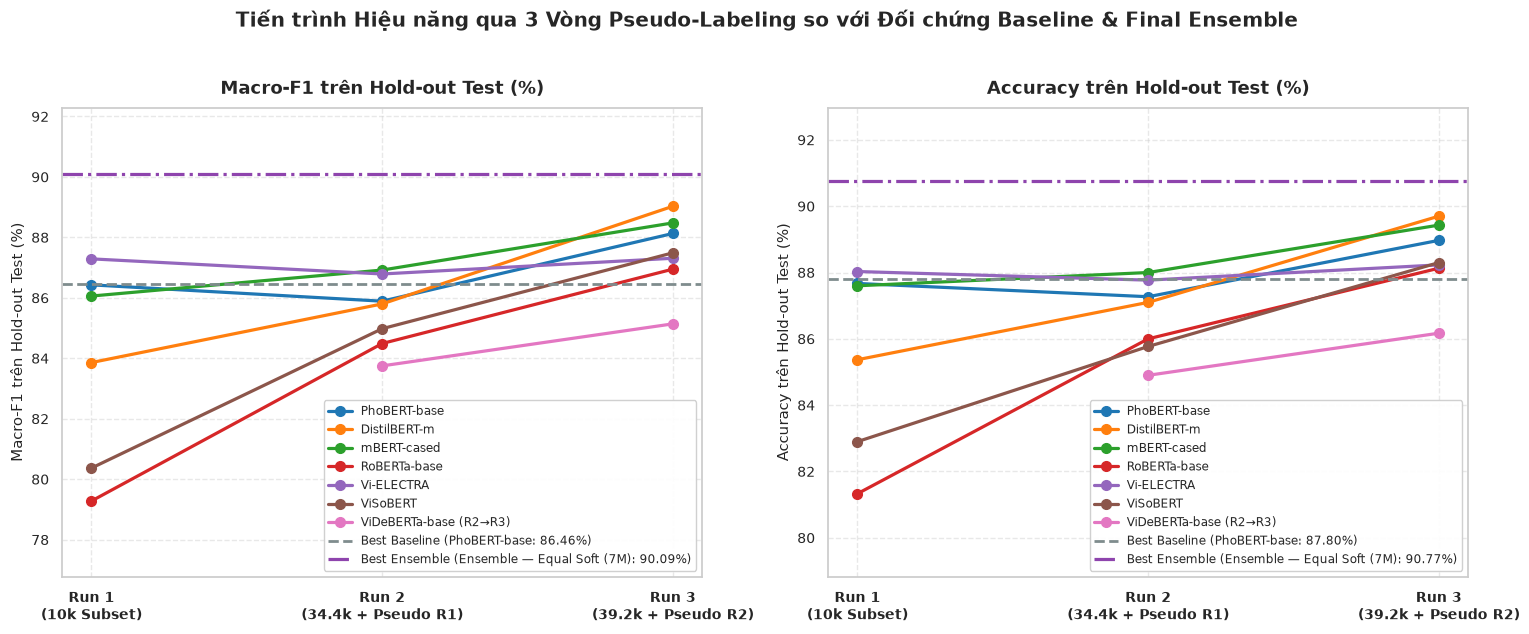

[Đã lưu biểu đồ] B8_02_radar_charts_7_models.png, B8_02_radar_charts_7_models.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report


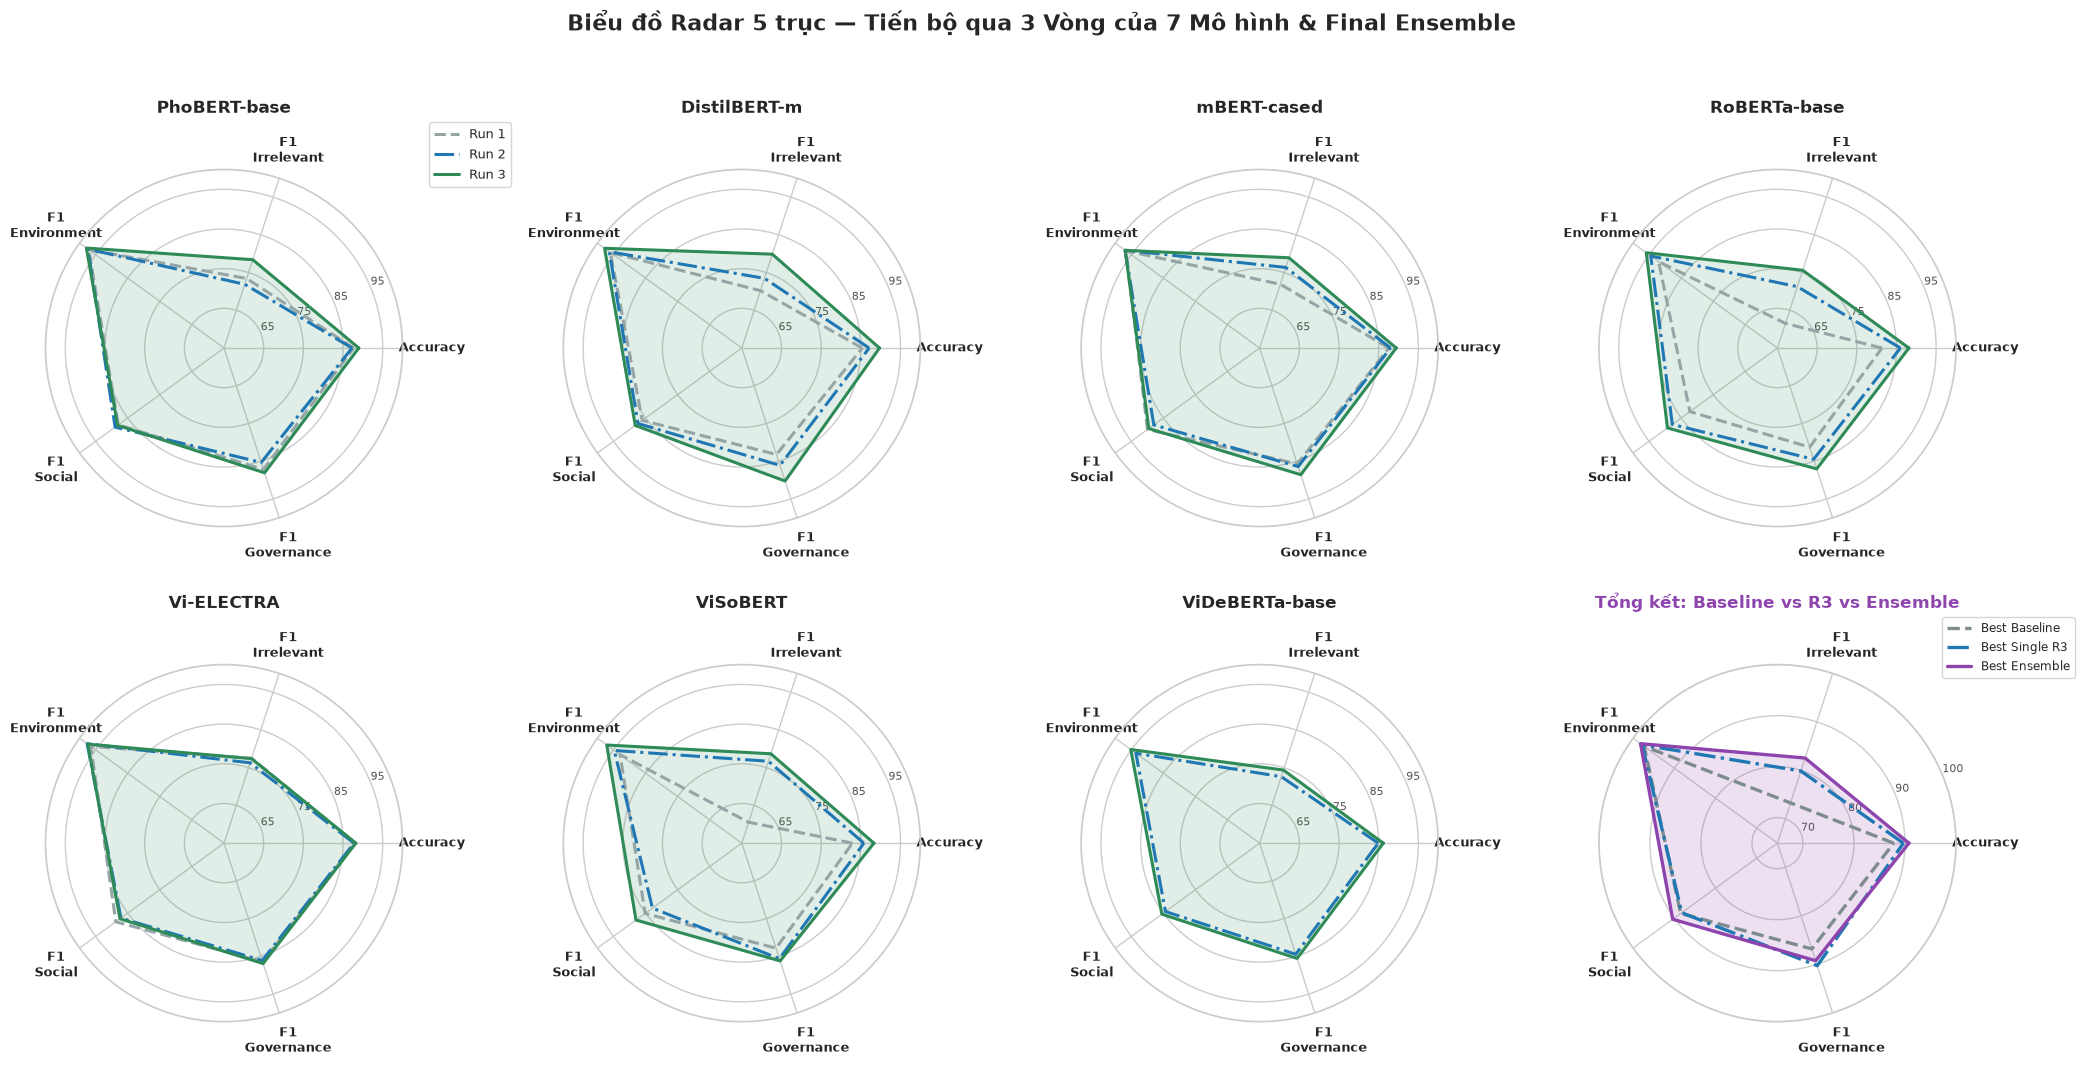

In [2]:
# Bước 8.2 — Biểu đồ B8.1 (Tiến trình 3 vòng + Ablation) & B8.2 (Lưới Radar 7 mô hình + Tổng kết)
fig1 = plot_ablation_and_3rounds_progress(
    all_runs_df=all_runs_df,
    save_dir=FIG_DIR,
    filename_stem="B8_01_tien_trinh_3_vong_va_ablation",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

fig2 = plot_radar_charts_grid(
    all_runs_df=all_runs_df,
    save_dir=FIG_DIR,
    filename_stem="B8_02_radar_charts_7_models",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

[Đã lưu biểu đồ] B8_03_heatmap_f1_theo_lop.png, B8_03_heatmap_f1_theo_lop.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report


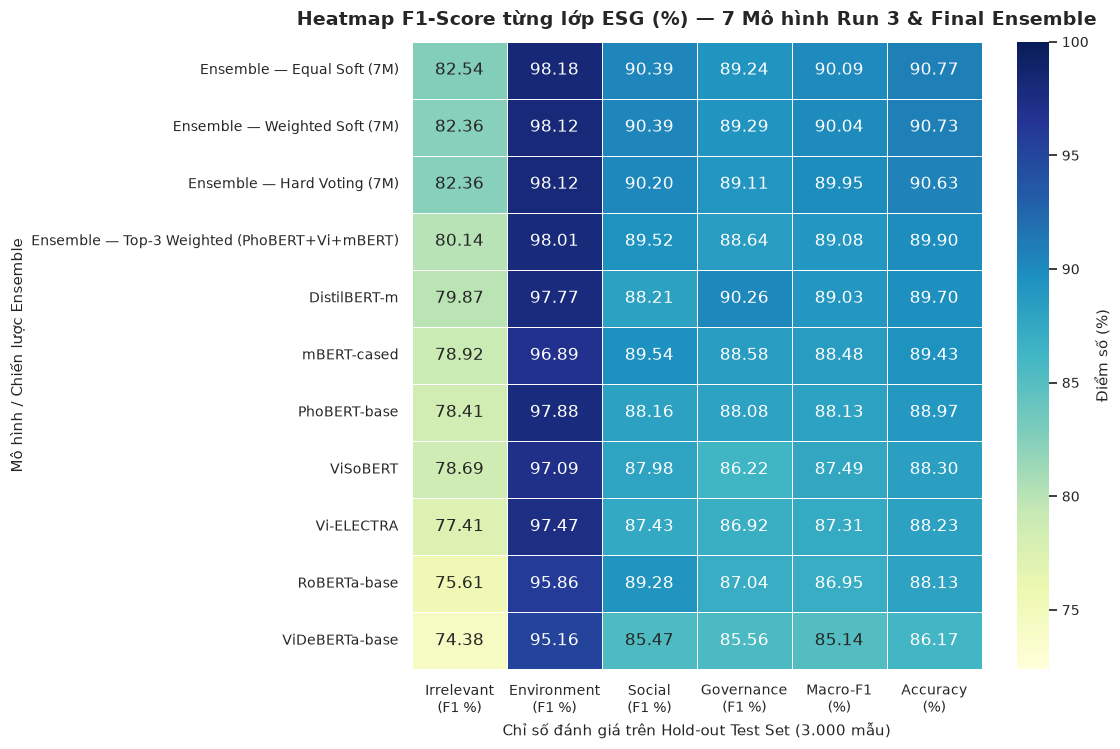

[Đã lưu biểu đồ] B8_04_confusion_matrix_best_va_ensemble.png, B8_04_confusion_matrix_best_va_ensemble.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report


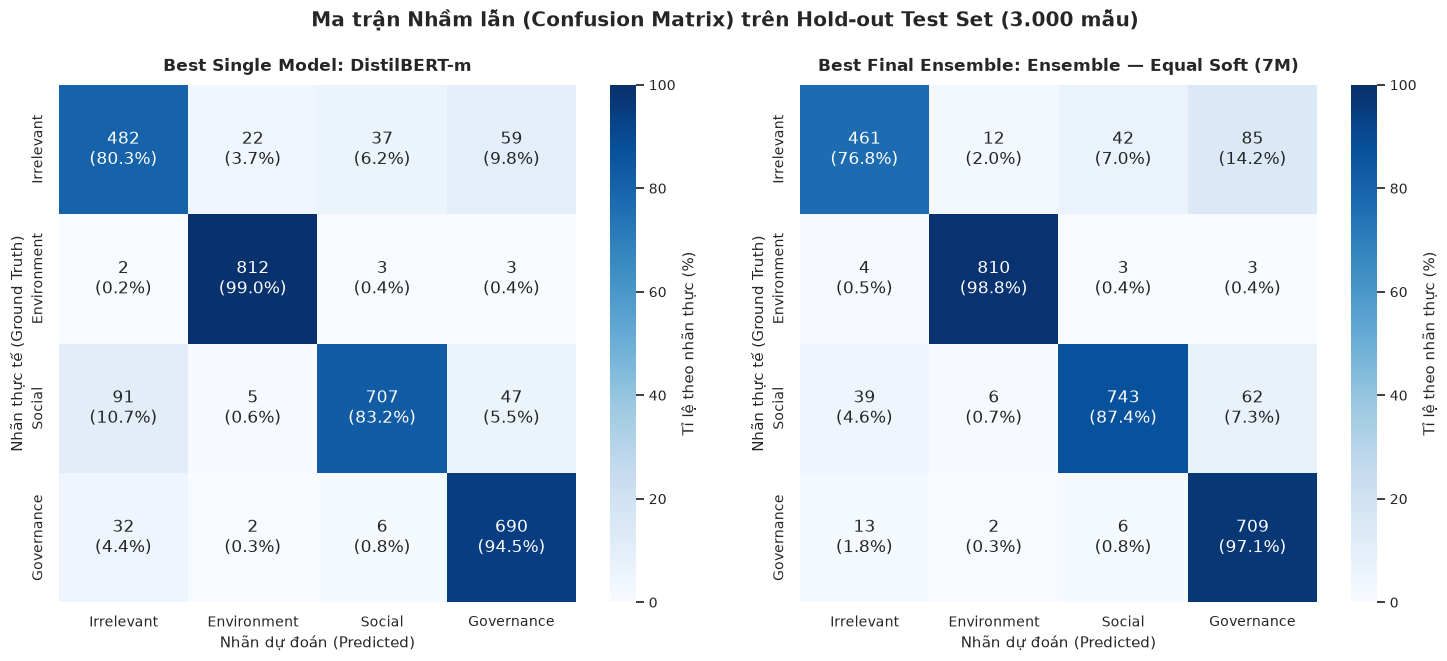

In [3]:
# Bước 8.3 — Biểu đồ B8.3 (Heatmap F1 từng lớp) & B8.4 (Confusion Matrix Best Single vs Final Ensemble)
fig3 = plot_per_class_f1_heatmap(
    run3_and_ens_df=b7_summary_df,
    save_dir=FIG_DIR,
    filename_stem="B8_03_heatmap_f1_theo_lop",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

fig4 = plot_dual_confusion_matrix(
    cm_best_single=best_r3_eval["confusion_matrix"],
    single_name=best_r3_display,
    cm_ensemble=best_ens_eval["confusion_matrix"],
    ensemble_name=best_ens_name,
    save_dir=FIG_DIR,
    filename_stem="B8_04_confusion_matrix_best_va_ensemble",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

[Đã lưu biểu đồ] B8_05_tradeoff_hieu_nang_va_toc_do.png, B8_05_tradeoff_hieu_nang_va_toc_do.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report


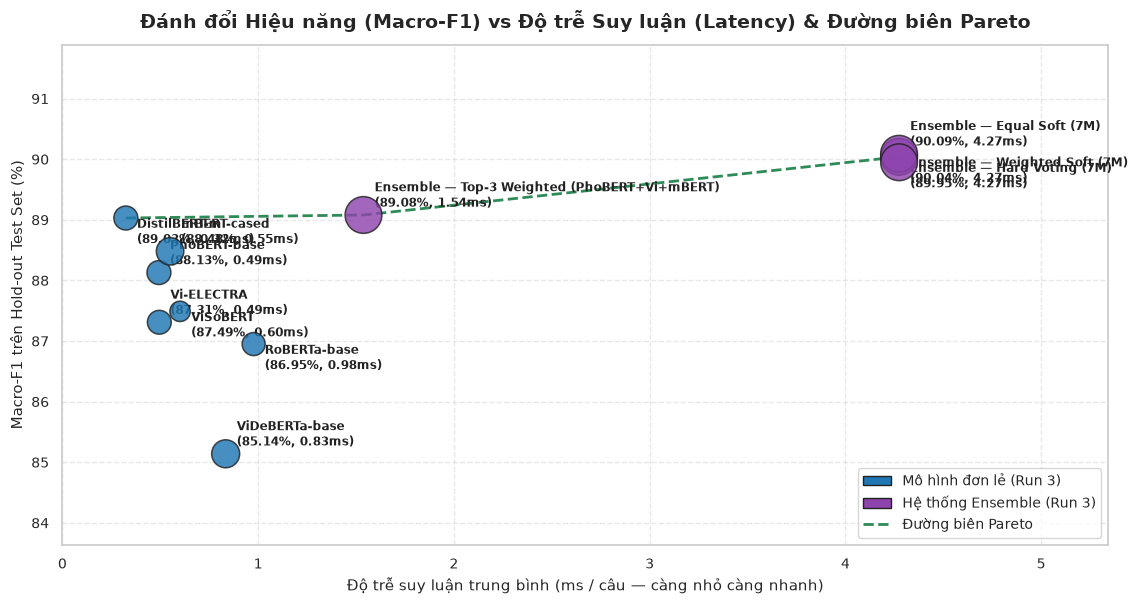

[Đã lưu biểu đồ] B8_06_calibration_reliability.png, B8_06_calibration_reliability.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B8_final_report


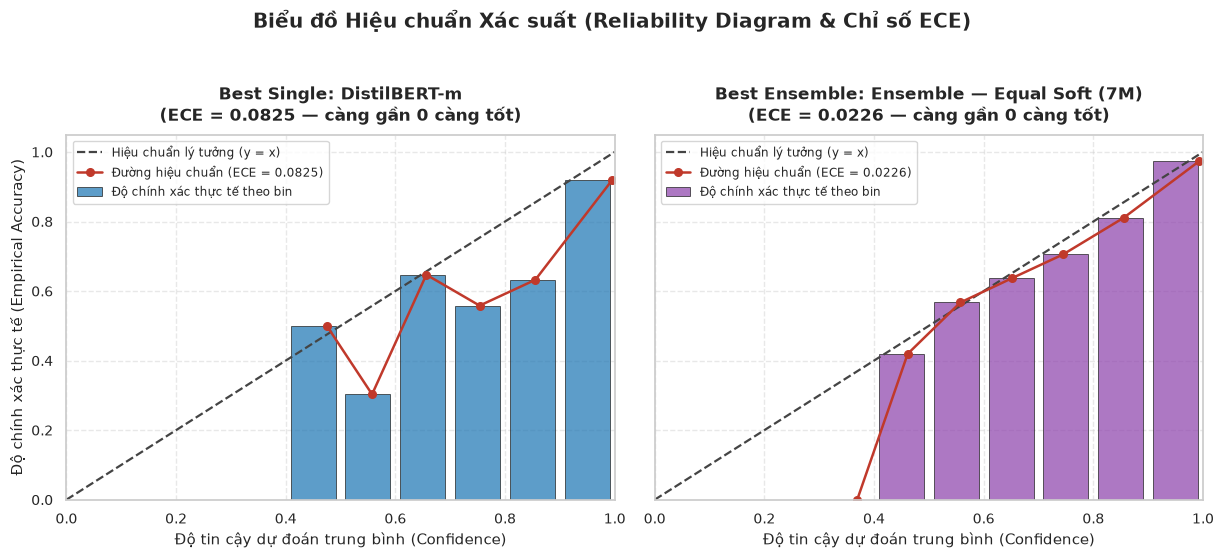


=== DANH SÁCH TRỌN BỘ BIỂU ĐỒ TỔNG KẾT TẠI B8_final_report ===
  - B8_01_tien_trinh_3_vong_va_ablation.pdf
  - B8_01_tien_trinh_3_vong_va_ablation.png
  - B8_02_radar_charts_7_models.pdf
  - B8_02_radar_charts_7_models.png
  - B8_03_heatmap_f1_theo_lop.pdf
  - B8_03_heatmap_f1_theo_lop.png
  - B8_04_confusion_matrix_best_va_ensemble.pdf
  - B8_04_confusion_matrix_best_va_ensemble.png
  - B8_05_tradeoff_hieu_nang_va_toc_do.pdf
  - B8_05_tradeoff_hieu_nang_va_toc_do.png
  - B8_06_calibration_reliability.pdf
  - B8_06_calibration_reliability.png


In [4]:
# Bước 8.4 — Biểu đồ B8.5 (Trade-off Macro-F1 vs Latency + Pareto) & B8.6 (Calibration Reliability Diagram)
fig5 = plot_accuracy_latency_tradeoff(
    tradeoff_df=b7_summary_df,
    save_dir=FIG_DIR,
    filename_stem="B8_05_tradeoff_hieu_nang_va_toc_do",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

cal_payload = {
    f"Best Single: {best_r3_display}": {
        "ece": best_r3_eval["overall_metrics"]["ece"],
        "calibration_bins": best_r3_eval["calibration_bins"],
    },
    f"Best Ensemble: {best_ens_name}": {
        "ece": best_ens_eval["overall_metrics"]["ece"],
        "calibration_bins": best_ens_eval["calibration_bins"],
    },
}
fig6 = plot_calibration_reliability_diagram(
    models_calibration=cal_payload,
    save_dir=FIG_DIR,
    filename_stem="B8_06_calibration_reliability",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

print("\n=== DANH SÁCH TRỌN BỘ BIỂU ĐỒ TỔNG KẾT TẠI B8_final_report ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")

---
## Phần 2 — Phân tích Lỗi chuyên sâu (Error Analysis trên Hold-out Test Set)

In [5]:
# Bước 8.5: Phân tích cặp nhầm lẫn phổ biến nhất, hiệu quả sửa lỗi của Ensemble & trích xuất Top-15 lỗi tự tin cao
ens_probs_df = pd.read_parquet(METRICS_DIR / "run3_final_ensemble_probs.parquet")
r3_probs_df = pd.read_parquet(METRICS_DIR / f"run3_{best_r3_short}_test_probs.parquet")

y_true = ens_probs_df["true_label"].to_numpy(dtype=int)
ens_preds = ens_probs_df["pred_label"].to_numpy(dtype=int)
r3_preds = r3_probs_df["pred_label"].to_numpy(dtype=int)
ens_probs = ens_probs_df[["prob_0", "prob_1", "prob_2", "prob_3"]].to_numpy(dtype=np.float32)

# 1. Thống kê số câu Ensemble sửa đúng cho Best Single Model
ens_fixed = int(np.sum((ens_preds == y_true) & (r3_preds != y_true)))
ens_broke = int(np.sum((ens_preds != y_true) & (r3_preds == y_true)))
total_wrong = int(np.sum(ens_preds != y_true))
print("=== PHÂN TÍCH ĐỊNH LƯỢNG LỖI TRÊN 3.000 MẪU HOLD-OUT TEST ===")
print(f"- Tổng số mẫu Final Ensemble đoán sai : {total_wrong:,} / {len(y_true):,} ({total_wrong/len(y_true)*100:.2f}%)")
print(f"- Số mẫu Best Single ({best_r3_display}) sai nhưng Ensemble SỬA ĐÚNG : +{ens_fixed:,} mẫu")
print(f"- Số mẫu Best Single ({best_r3_display}) đúng nhưng Ensemble đoán sai: -{ens_broke:,} mẫu")
print(f"- Lợi ích ròng của Ensemble (Net gain)                               : {ens_fixed - ens_broke:+,} mẫu")

# 2. Bảng các cặp nhầm lẫn (True -> Pred) phổ biến nhất
wrong_idx = np.where(ens_preds != y_true)[0]
pair_counts = (
    pd.DataFrame({
        "Nhãn thực (True)": [ID2LABEL[int(y_true[i])] for i in wrong_idx],
        "Nhãn đoán (Pred)": [ID2LABEL[int(ens_preds[i])] for i in wrong_idx],
    })
    .value_counts()
    .reset_index(name="Số lượng lỗi")
)
pair_counts["Tỉ lệ trong tổng lỗi (%)"] = (pair_counts["Số lượng lỗi"] / max(total_wrong, 1) * 100.0).round(2)
pair_counts.to_csv(METRICS_DIR / "B8_confusion_pairs.csv", index=False, encoding="utf-8-sig")
print("\n=== CÁC CẶP NHẦM LẪN PHỔ BIẾN NHẤT ===")
display(pair_counts)

# 3. Trích xuất Top-15 mẫu dự đoán sai có độ tin cậy cao nhất
evaluator = ESGEvaluator(LABEL_NAMES)
top15_err = evaluator.extract_top_errors(test_df, y_true, ens_probs, text_col=cfg.text_column, top_k=15)
top15_err.to_csv(METRICS_DIR / "B8_top15_errors.csv", index=False, encoding="utf-8-sig")
print(f"\n[Đã lưu] {METRICS_DIR / 'B8_top15_errors.csv'} & B8_confusion_pairs.csv")
preview_err = top15_err.copy()
preview_err["vi_text"] = preview_err["vi_text"].str.slice(0, 140)
display(preview_err[["true_label", "pred_label", "pred_confidence", "true_class_prob", "vi_text"]])

=== PHÂN TÍCH ĐỊNH LƯỢNG LỖI TRÊN 3.000 MẪU HOLD-OUT TEST ===
- Tổng số mẫu Final Ensemble đoán sai : 277 / 3,000 (9.23%)
- Số mẫu Best Single (DistilBERT-m) sai nhưng Ensemble SỬA ĐÚNG : +99 mẫu
- Số mẫu Best Single (DistilBERT-m) đúng nhưng Ensemble đoán sai: -67 mẫu
- Lợi ích ròng của Ensemble (Net gain)                               : +32 mẫu

=== CÁC CẶP NHẦM LẪN PHỔ BIẾN NHẤT ===


,Nhãn thực (True),Nhãn đoán (Pred),Số lượng lỗi,Tỉ lệ trong tổng lỗi (%)
0,Irrelevant,Governance,85,30.69
1,Social,Governance,62,22.38
2,Irrelevant,Social,42,15.16
3,Social,Irrelevant,39,14.08
4,Governance,Irrelevant,13,4.69
5,Irrelevant,Environment,12,4.33
6,Governance,Social,6,2.17
7,Social,Environment,6,2.17
8,Environment,Irrelevant,4,1.44
9,Environment,Governance,3,1.08



[Đã lưu] D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\metrics\B8_top15_errors.csv & B8_confusion_pairs.csv


,true_label,pred_label,pred_confidence,true_class_prob,vi_text
0,Irrelevant,Environment,0.999720,0.000085,"điểm nổi bật của greco 2024 là khu vực ""techma..."
1,Irrelevant,Governance,0.999309,0.000498,sự tồn tại liên tục và tính khả thi về tài chí...
2,Irrelevant,Governance,0.999306,0.000488,những vấn đề chúng ta trong nỗ lực duy trì một...
3,Social,Governance,0.999299,0.000384,chủ đề nóng lên trả lời của chúng quả phát sin...
4,Social,Governance,0.998949,0.000151,"sự quan trọng của việc nắm bắt esg đồng thời, ..."
5,Irrelevant,Governance,0.998896,0.000758,tiếp theo việc hợp nhất fp gmbh và công nhận k...
6,Social,Governance,0.998785,0.000702,công ty chúng tôi đạt được một số tiến triển q...
7,Social,Governance,0.998732,0.000715,các buổi họp nhóm tập trung cung cấp cho hội đ...
8,Irrelevant,Environment,0.998730,0.000963,94% vật liệu trong bao bì được làm từ vật liệu...
9,Irrelevant,Governance,0.998337,0.001386,cô ấy có khả năng lãnh đạo xuất sắc trong chiế...


---
## Phần 3 — Demo Tương tác Phân loại Văn bản ESG Tiếng Việt (`ipywidgets`)

> Demo nạp **Top-3 mô hình mạnh nhất ở Run 3** (vừa đạt độ chính xác cao tương đương Full-7 Ensemble, vừa siêu nhẹ chỉ chiếm ~1.5 GB VRAM RTX 5070!). Sau khi trải nghiệm xong, bấm nút **"Giải phóng VRAM Demo"** để trả sạch bộ nhớ GPU.

In [7]:
# Bước 8.6: Khởi tạo ứng dụng Demo phân loại văn bản ESG tương tác ngay trên JupyterLab
import ipywidgets as widgets
from IPython.display import display, clear_output

# Tự động chọn Top-3 mô hình Run 3 theo Val Macro-F1 để làm động cơ Demo nhẹ & chính xác
r3_sorted = b7_summary_df[b7_summary_df["run_tag"] == "run3"].sort_values("val_f1_macro_pct", ascending=False)
demo_short_names = r3_sorted["model_short_name"].head(3).tolist()
demo_weights = r3_sorted["val_f1_macro_pct"].head(3).to_numpy(dtype=np.float64)
demo_weights = demo_weights / demo_weights.sum()

print(f"Đang nạp Top-3 mô hình Run 3 cho Demo tương tác: {demo_short_names}...")
demo_engines = []
for short_name, w in zip(demo_short_names, demo_weights):
    spec = MODEL_REGISTRY[short_name]
    ckpt_dir = CHECKPOINTS_DIR / "run3" / short_name
    wrapper = ESGModelWrapper(ckpt_dir).load()
    prep = VietnameseESGPreprocessor(use_word_segmenter=spec.use_word_segmenter)
    demo_engines.append((spec, wrapper, prep, float(w)))
print("[SẴN SÀNG] Đã nạp xong 3 mô hình Demo!")

# Bộ 4 câu mẫu ESG tiếng Việt thực tế để bấm thử nhanh khi bảo vệ đồ án
SAMPLE_TEXTS = {
    "Mẫu Environment": "Tập đoàn cam kết cắt giảm 45% lượng phát thải khí nhà kính phạm vi 1 và 2 vào năm 2030 thông qua chuyển đổi sang điện mặt trời áp mái và tái chế 90% nước thải công nghiệp.",
    "Mẫu Social": "Trong năm tài chính vừa qua, doanh nghiệp đã chi hơn 120 tỷ đồng cho các chương trình đào tạo nâng cao tay nghề nhân viên, bảo hiểm sức khỏe toàn diện và học bổng cho học sinh vùng cao.",
    "Mẫu Governance": "Hội đồng quản trị đã ban hành quy chế quản trị rủi ro cập nhật, thiết lập Ủy ban Kiểm toán độc lập gồm 100% thành viên không điều hành nhằm đảm bảo tính minh bạch với cổ đông.",
    "Mẫu Irrelevant": "Doanh thu quý 3 của công ty tăng trưởng ổn định nhờ mở rộng thêm 12 điểm bán mới tại khu vực miền Trung và tối ưu hóa chi phí vận chuyển kho bãi.",
}

text_area = widgets.Textarea(
    value=SAMPLE_TEXTS["Mẫu Environment"],
    placeholder="Nhập câu hoặc đoạn trích báo cáo doanh nghiệp tiếng Việt tại đây...",
    description="Văn bản:",
    layout=widgets.Layout(width="96%", height="95px"),
)
sample_dropdown = widgets.Dropdown(
    options=list(SAMPLE_TEXTS.keys()),
    description="Chọn mẫu:",
    layout=widgets.Layout(width="320px"),
)
btn_predict = widgets.Button(description="Phân loại ESG", button_style="success", icon="play")
btn_release = widgets.Button(description="Giải phóng VRAM Demo", button_style="warning", icon="trash")
out_box = widgets.Output()

def _on_sample_change(change):
    if change["name"] == "value":
        text_area.value = SAMPLE_TEXTS[change["new"]]

def _on_predict(_):
    with out_box:
        clear_output(wait=True)
        raw_txt = text_area.value.strip()
        if not raw_txt:
            print("Vui lòng nhập văn bản tiếng Việt để phân loại.")
            return
        if not demo_engines:
            print("Các mô hình Demo đã được giải phóng khỏi VRAM — chạy lại cell này để nạp lại.")
            return

        ens_probs = np.zeros(4, dtype=np.float64)
        vote_rows = []
        for spec, wrapper, prep, w in demo_engines:
            proc_txt = prep.segment_text(raw_txt)
            probs = wrapper.predict_proba([proc_txt], batch_size=1, max_length=cfg.max_length, use_bf16=not spec.force_fp32, show_progress=False)[0]
            ens_probs += w * probs
            pred_id = int(np.argmax(probs))
            vote_rows.append({
                "Mô hình": spec.display_name,
                "Trọng số": round(w, 3),
                "Nhãn bầu": ID2LABEL[pred_id],
                "Độ tin cậy": f"{probs[pred_id]*100:.2f}%",
            })

        final_id = int(np.argmax(ens_probs))
        final_conf = float(ens_probs[final_id]) * 100.0
        print("=" * 74)
        print(f"KẾT QUẢ DỰ ĐOÁN ENSEMBLE: {LABEL_NAMES_VI[final_id]} — Độ tin cậy: {final_conf:.2f}%")
        print("=" * 74)
        display(pd.DataFrame(vote_rows))

        fig, ax = plt.subplots(figsize=(7.5, 2.8))
        colors = [ESG_PALETTE[n] for n in LABEL_NAMES]
        bars = ax.barh(LABEL_NAMES, ens_probs * 100.0, color=colors, edgecolor="#222222", linewidth=0.6)
        ax.set_xlim(0, 112)
        ax.set_xlabel("Xác suất dự đoán Ensemble (%)")
        ax.set_title("Phân phối Xác suất 4 lớp ESG", fontweight="bold")
        for bar, val in zip(bars, ens_probs * 100.0):
            ax.text(val + 1.2, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontweight="bold", fontsize=9.5)
        plt.tight_layout()
        plt.show()

def _on_release(_):
    with out_box:
        for _, wrapper, _, _ in demo_engines:
            wrapper.release_memory()
        demo_engines.clear()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print("[OK] Đã giải phóng toàn bộ VRAM của các mô hình Demo!")

sample_dropdown.observe(_on_sample_change, names="value")
btn_predict.on_click(_on_predict)
btn_release.on_click(_on_release)

display(widgets.VBox([widgets.HBox([sample_dropdown, btn_predict, btn_release]), text_area, out_box]))

Đang nạp Top-3 mô hình Run 3 cho Demo tương tác: ['phobert-base', 'electra-base-vn', 'bert-base-multilingual-cased']...
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\phobert-base
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\electra-base-vn
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\bert-base-multilingual-cased
[SẴN SÀNG] Đã nạp xong 3 mô hình Demo!
